   # CM2604 Machine Learning – Telco Customer Churn Prediction
   **Student:** Charuka Jayasena
   **Task:** Predict whether a customer will churn

In [1]:
# Core libraries
import numpy as np                 # numerical arrays and maths
import pandas as pd                # tables
import matplotlib.pyplot as plt    # plotting
import seaborn as sns              # nicer statistical plots
import warnings, os
warnings.filterwarnings('ignore')  # hide non-critical warnings

RANDOM_STATE = 42                  # fixed seed so results are reproducible
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', palette='Set2')
os.makedirs('figures', exist_ok=True)   # folder to save charts for the report

print("Setup complete")

Setup complete


## 0.1 Load the dataset
The *Telco Customer Churn* dataset (IBM sample data, also on Kaggle as `blastchar/telco-customer-churn`) contains 7,043 customers and 21 columns. It was downloaded from Kaggle and stored in this repository's data/ folder, so the notebook always uses the same version of the data.

In [2]:
# Dataset stored in this project's own GitHub repo (data/ folder)
DATA_URL = 'https://raw.githubusercontent.com/charuka200/telco-churn-ml/refs/heads/main/data/WA_Fn-UseC_-Telco-Customer-Churn.csv'

df_raw = pd.read_csv(DATA_URL)   # original data – never modified
df = df_raw.copy()               # working copy used for EDA

print('Shape (rows, columns):', df.shape)
df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()  # quick overview of the data types and missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


# 1. Task 1 – Exploratory Data Analysis
### 1.1 Metadata: data types, unique values and missing values

In [4]:
# Overview of every column: type, number of unique values, missing values, example value
meta = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(),
    'missing (NaN)': df.isna().sum(),
    'example': df.iloc[0]
})
meta

,dtype,n_unique,missing (NaN),example
customerID,object,7043,0,7590-VHVEG
gender,object,2,0,Female
SeniorCitizen,int64,2,0,0
Partner,object,2,0,Yes
Dependents,object,2,0,No
tenure,int64,73,0,1
PhoneService,object,2,0,No
MultipleLines,object,3,0,No phone service
InternetService,object,3,0,DSL
OnlineSecurity,object,3,0,No


`TotalCharges` is stored as text (object) although it should be numeric. Converting it reveals hidden missing values (blank strings), which `isna()` cannot detect.

In [5]:
# Convert TotalCharges to numbers; blanks become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print('Missing TotalCharges after conversion:', df['TotalCharges'].isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate customerIDs:', df['customerID'].duplicated().sum())

# Show the rows with missing TotalCharges
df[df['TotalCharges'].isna()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Missing TotalCharges after conversion: 11
Duplicate rows: 0
Duplicate customerIDs: 0


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


### 1.2 Class distribution (target variable)

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54


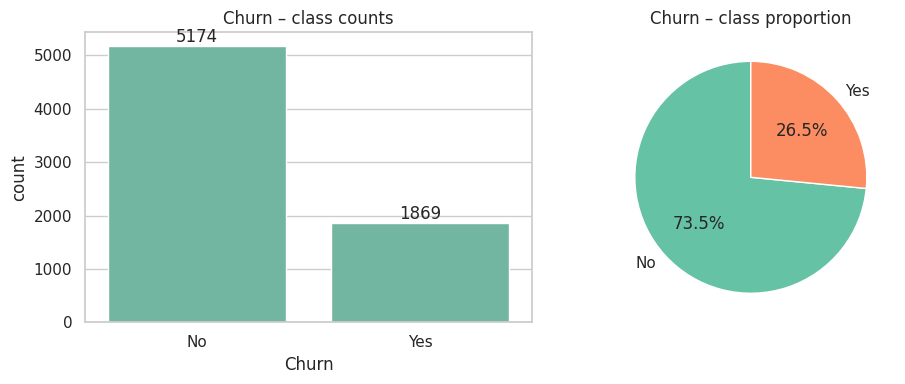

In [6]:
# Count and percentage of each class
counts = df['Churn'].value_counts()
pct = df['Churn'].value_counts(normalize=True) * 100
print(pd.DataFrame({'count': counts, 'percent': pct.round(2)}))

# Bar chart + pie chart side by side
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=df, x='Churn', ax=ax[0])
for c in ax[0].containers:
    ax[0].bar_label(c)                      # write the count on each bar
ax[0].set_title('Churn – class counts')

ax[1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90,
          colors=sns.color_palette('Set2'))
ax[1].set_title('Churn – class proportion')

plt.tight_layout()
plt.savefig('figures/01_class_distribution.png', bbox_inches='tight')   # save for the report
plt.show()

**Insight:** The classes are imbalanced (≈73% No vs ≈27% Yes). Accuracy alone would be misleading: a model that always predicts "No" would already score ≈73%. Therefore we use a stratified train/test split, handle imbalance during training, and compare models mainly on F1, Recall and ROC-AUC.

### 1.3 Attribute statistics

In [7]:
# Summary statistics for the numerical attributes
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
desc = df[num_cols].describe().T
desc['skew'] = df[num_cols].skew()      # >0 = long right tail
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,0.24
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,-0.22
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80,0.96


In [8]:
# Mean and median of each numeric attribute, split by churn class
df.groupby('Churn')[num_cols].agg(['mean', 'median']).round(2)

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2555.34  1683.60
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

In [9]:
# Value counts for every categorical attribute
cat_cols_eda = [c for c in df.columns if c not in num_cols + ['customerID', 'Churn']]
print(f'{len(cat_cols_eda)} categorical attributes:\n')
for c in cat_cols_eda:
    print(f'{c:18s}', df[c].value_counts().to_dict())

16 categorical attributes:

gender             {'Male': 3555, 'Female': 3488}
SeniorCitizen      {0: 5901, 1: 1142}
Partner            {'No': 3641, 'Yes': 3402}
Dependents         {'No': 4933, 'Yes': 2110}
PhoneService       {'Yes': 6361, 'No': 682}
MultipleLines      {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService    {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity     {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup       {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection   {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport        {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV        {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies    {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract           {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling   {'Yes': 4171, 'No': 2872}
PaymentMethod      {'Electronic check': 2365,

### 1.4 Numerical attributes vs churn

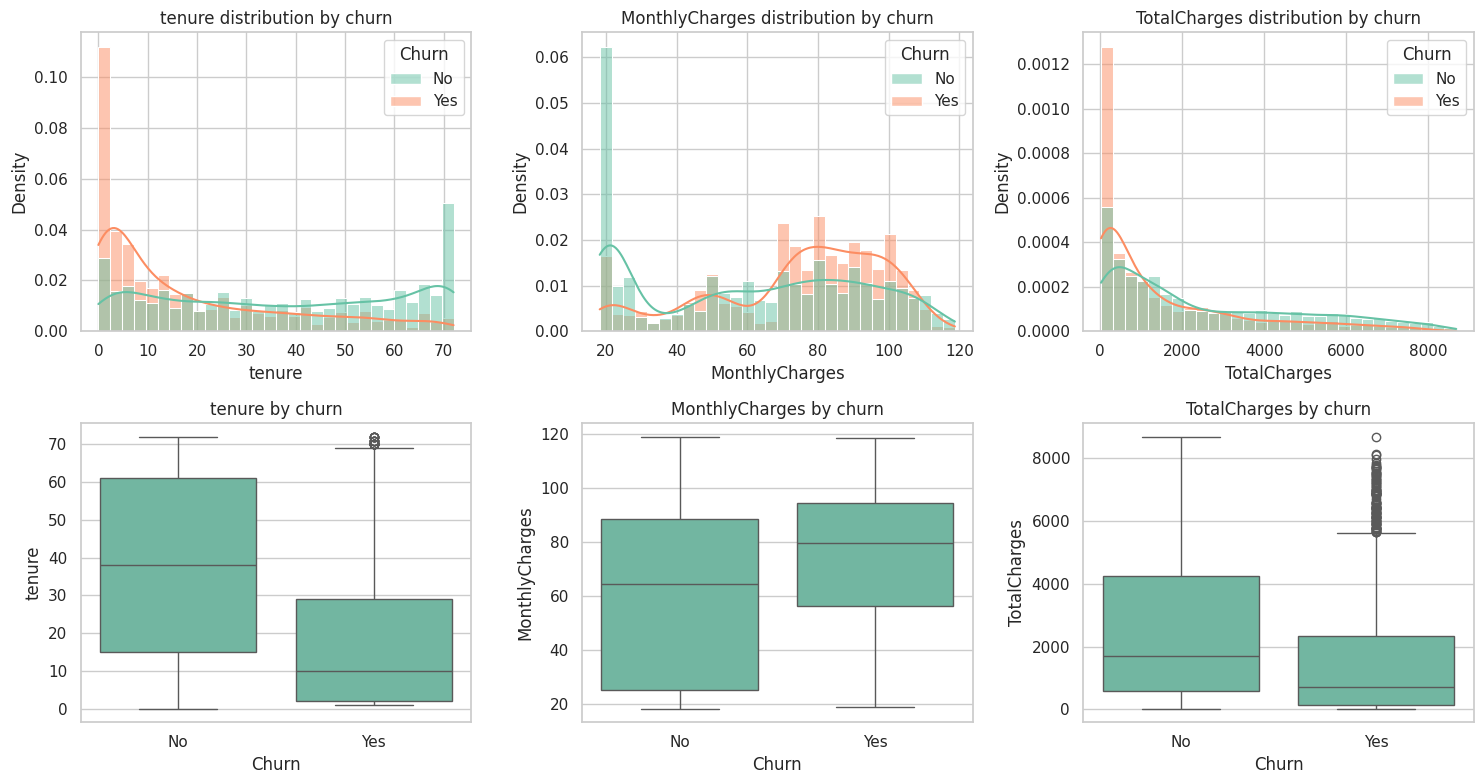

In [10]:
# Top row: distributions (histogram + density curve) for each class
# Bottom row: boxplots comparing churners vs non-churners
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue='Churn', kde=True, stat='density',
                 common_norm=False, bins=30, ax=axes[0, i])
    axes[0, i].set_title(f'{col} distribution by churn')

    sns.boxplot(data=df, x='Churn', y=col, ax=axes[1, i])
    axes[1, i].set_title(f'{col} by churn')

plt.tight_layout()
plt.savefig('figures/02_numeric_vs_churn.png', bbox_inches='tight')
plt.show()

**Insights:**
- Churners have much **lower tenure** (median ≈10 months vs ≈38): customers are most likely to leave early in their lifetime.
- Churners pay **higher monthly charges** (median ≈$80 vs ≈$64).
- `TotalCharges` is strongly right-skewed; churners have lower totals because they leave sooner.